<a href="https://colab.research.google.com/github/yeminaung-web/AI_STUDY/blob/main/UCI_HAR/UCI_HAR(CNN_%2B_LSTM%2C_OG).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

"""
UCI-HAR Classification using CNN + LSTM
TensorFlow / Keras

Input:
    UCI-HAR Inertial Signals
    Shape = (samples, 128, 9)

Channels:
    body_acc_x
    body_acc_y
    body_acc_z
    body_gyro_x
    body_gyro_y
    body_gyro_z
    total_acc_x
    total_acc_y
    total_acc_z

Classes:
    0: WALKING
    1: WALKING_UPSTAIRS
    2: WALKING_DOWNSTAIRS
    3: SITTING
    4: STANDING
    5: LAYING
"""


'\nUCI-HAR Classification using CNN + LSTM\nTensorFlow / Keras\n\nInput:\n    UCI-HAR Inertial Signals\n    Shape = (samples, 128, 9)\n\nChannels:\n    body_acc_x\n    body_acc_y\n    body_acc_z\n    body_gyro_x\n    body_gyro_y\n    body_gyro_z\n    total_acc_x\n    total_acc_y\n    total_acc_z\n\nClasses:\n    0: WALKING\n    1: WALKING_UPSTAIRS\n    2: WALKING_DOWNSTAIRS\n    3: SITTING\n    4: STANDING\n    5: LAYING\n'

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [12]:

# ============================================================
# 1. CONFIGURATION
# ============================================================

DATASET_PATH = "/content/drive/MyDrive/Colab Notebooks/human+activity+recognition+using+smartphones/UCI HAR Dataset"

SEED = 42
VALIDATION_RATIO = 0.20

BATCH_SIZE = 64
EPOCHS = 100
LEARNING_RATE = 0.001

MODEL_PATH = "best_cnn_lstm_uci_har.keras"





In [13]:

# ============================================================
# 2. IMPORT LIBRARIES
# ============================================================

import os
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    BatchNormalization,
    LSTM,
    Dense,
    Dropout
)



from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)



In [14]:

# ============================================================
# 3. RANDOM SEED
# ============================================================

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


print("=" * 70)
print("TensorFlow version:", tf.__version__)
print("=" * 70)



TensorFlow version: 2.21.0


In [15]:

# ============================================================
# 4. SIGNAL / CLASS NAMES
# ============================================================

SIGNAL_NAMES = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",

    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",

    "total_acc_x",
    "total_acc_y",
    "total_acc_z"
]


CLASS_NAMES = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]



In [16]:

# ============================================================
# 5. LOAD INERTIAL SIGNALS
# ============================================================

def load_inertial_signals(dataset_path, split):

    """
    Load 9-channel UCI-HAR inertial signals.

    Each signal file:
        shape = (N, 128)

    After stacking:
        shape = (N, 128, 9)
    """

    signal_folder = os.path.join(
        dataset_path,
        split,
        "Inertial Signals"
    )

    signals = []

    for signal_name in SIGNAL_NAMES:

        filename = f"{signal_name}_{split}.txt"

        file_path = os.path.join(
            signal_folder,
            filename
        )

        if not os.path.exists(file_path):
            raise FileNotFoundError(
                f"File not found: {file_path}"
            )

        signal = np.loadtxt(
            file_path,
            dtype=np.float32
        )

        print(
            f"{split:5s} | "
            f"{signal_name:20s} | "
            f"{signal.shape}"
        )

        signals.append(signal)

    # (N, 128, 9)
    X = np.stack(
        signals,
        axis=-1
    )

    return X


In [17]:


# ============================================================
# 6. LOAD LABELS
# ============================================================

def load_labels(dataset_path, split):

    label_path = os.path.join(
        dataset_path,
        split,
        f"y_{split}.txt"
    )

    y = np.loadtxt(
        label_path,
        dtype=np.int32
    )

    # Original UCI-HAR labels:
    # 1 ~ 6
    #
    # TensorFlow:
    # 0 ~ 5

    y = y - 1

    return y



In [18]:

# ============================================================
# 7. LOAD TRAIN / TEST DATA
# ============================================================

print("\nLoading training data...\n")

X_train_full = load_inertial_signals(
    DATASET_PATH,
    "train"
)

y_train_full = load_labels(
    DATASET_PATH,
    "train"
)


print("\nLoading test data...\n")

X_test = load_inertial_signals(
    DATASET_PATH,
    "test"
)

y_test = load_labels(
    DATASET_PATH,
    "test"
)


print("\n" + "=" * 70)
print("Original dataset")
print("=" * 70)

print(
    "X_train_full:",
    X_train_full.shape
)

print(
    "y_train_full:",
    y_train_full.shape
)

print(
    "X_test:",
    X_test.shape
)

print(
    "y_test:",
    y_test.shape
)




Loading training data...

train | body_acc_x           | (7352, 128)
train | body_acc_y           | (7352, 128)
train | body_acc_z           | (7352, 128)
train | body_gyro_x          | (7352, 128)
train | body_gyro_y          | (7352, 128)
train | body_gyro_z          | (7352, 128)
train | total_acc_x          | (7352, 128)
train | total_acc_y          | (7352, 128)
train | total_acc_z          | (7352, 128)

Loading test data...

test  | body_acc_x           | (2947, 128)
test  | body_acc_y           | (2947, 128)
test  | body_acc_z           | (2947, 128)
test  | body_gyro_x          | (2947, 128)
test  | body_gyro_y          | (2947, 128)
test  | body_gyro_z          | (2947, 128)
test  | total_acc_x          | (2947, 128)
test  | total_acc_y          | (2947, 128)
test  | total_acc_z          | (2947, 128)

Original dataset
X_train_full: (7352, 128, 9)
y_train_full: (7352,)
X_test: (2947, 128, 9)
y_test: (2947,)


In [19]:

# ============================================================
# 8. TRAIN / VALIDATION SPLIT
# ============================================================

X_train, X_val, y_train, y_val = train_test_split(

    X_train_full,
    y_train_full,

    test_size=VALIDATION_RATIO,

    random_state=SEED,

    stratify=y_train_full
)


print("\n" + "=" * 70)
print("Dataset split")
print("=" * 70)

print(
    "Train:",
    X_train.shape
)

print(
    "Validation:",
    X_val.shape
)

print(
    "Test:",
    X_test.shape
)




Dataset split
Train: (5881, 128, 9)
Validation: (1471, 128, 9)
Test: (2947, 128, 9)


In [20]:

# ============================================================
# 9. STANDARD SCALER
# ============================================================

"""
Original shape:

    (samples, 128, 9)

StandardScaler requires:

    (observations, features)

Therefore reshape:

    (samples * 128, 9)

The 9 sensor channels are standardized independently.

IMPORTANT:
    scaler.fit() is performed ONLY on training data.
"""


num_channels = X_train.shape[-1]

scaler = StandardScaler()


# ------------------------------------------------------------
# Fit scaler using training data only
# ------------------------------------------------------------

X_train_2d = X_train.reshape(
    -1,
    num_channels
)

scaler.fit(
    X_train_2d
)


# ------------------------------------------------------------
# Transform function
# ------------------------------------------------------------

def standardize_data(X, scaler):

    original_shape = X.shape

    X_2d = X.reshape(
        -1,
        original_shape[-1]
    )

    X_scaled = scaler.transform(
        X_2d
    )

    X_scaled = X_scaled.reshape(
        original_shape
    )

    return X_scaled.astype(
        np.float32
    )


# ------------------------------------------------------------
# Apply StandardScaler
# ------------------------------------------------------------

X_train = standardize_data(
    X_train,
    scaler
)

X_val = standardize_data(
    X_val,
    scaler
)

X_test = standardize_data(
    X_test,
    scaler
)


print("\n" + "=" * 70)
print("StandardScaler")
print("=" * 70)

print(
    "Training channel means:"
)

print(
    np.round(
        np.mean(
            X_train,
            axis=(0, 1)
        ),
        4
    )
)

print(
    "\nTraining channel standard deviations:"
)

print(
    np.round(
        np.std(
            X_train,
            axis=(0, 1)
        ),
        4
    )
)




StandardScaler
Training channel means:
[ 0.  0.  0.  0.  0. -0.  0. -0.  0.]

Training channel standard deviations:
[0.9997 0.9995 0.9994 0.9997 0.9996 0.9996 0.9997 0.9998 0.9998]


In [21]:
#Using CNN + LSTM layer

def build_model():

    model = Sequential([

        Input(shape=(128, 9)),

        # CNN Block 1
        Conv1D(filters=64, kernel_size=5, padding="same", activation="relu"),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        Dropout(0.30),

        # CNN Block 2
        Conv1D(filters=128, kernel_size=5, padding="same", activation="relu"),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        Dropout(0.30),

        # LSTM Layer
        LSTM(units=128),
        Dropout(0.30),

        # Dense Classifier
        Dense(units=64, activation="relu"),
        Dropout(0.30),
        Dense(units=6, activation="softmax")
    ])

    return model

model = build_model()

In [22]:

# ============================================================
# 11. COMPILE
# ============================================================

optimizer = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)


model.compile(

    optimizer=optimizer,

    loss="sparse_categorical_crossentropy",

    metrics=[
        "accuracy"
    ]
)


print("\n")
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 128, 64)        │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 64, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 185,030 (722.77 KB)

 Trainable params: 184,646 (721.27 KB)

 Non-trainable params: 384 (1.50 KB)

In [23]:


# ============================================================
# 12. CALLBACKS
# ============================================================

callbacks = [

    EarlyStopping(

        monitor="val_loss",

        patience=15,

        restore_best_weights=True,

        verbose=1
    ),


    ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=5,

        min_lr=1e-6,

        verbose=1
    ),


    ModelCheckpoint(

        filepath=MODEL_PATH,

        monitor="val_loss",

        save_best_only=True,

        verbose=1
    )
]



In [24]:

# ============================================================
# 13. TRAIN
# ============================================================

print("\n" + "=" * 70)
print("Training Simple RNN")
print("=" * 70)


history = model.fit(

    X_train,
    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    callbacks=callbacks,

    verbose=1
)




Training Simple RNN
Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - accuracy: 0.6894 - loss: 0.8276
Epoch 1: val_loss improved from None to 0.24378, saving model to best_cnn_lstm_uci_har.keras

Epoch 1: finished saving model to best_cnn_lstm_uci_har.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 170ms/step - accuracy: 0.8152 - loss: 0.4963 - val_accuracy: 0.9300 - val_loss: 0.2438 - learning_rate: 0.0010
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.9347 - loss: 0.1840
Epoch 2: val_loss improved from 0.24378 to 0.19983, saving model to best_cnn_lstm_uci_har.keras

Epoch 2: finished saving model to best_cnn_lstm_uci_har.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 14s 155ms/step - accuracy: 0.9371 - loss: 0.1659 - val_accuracy: 0.9313 - val_loss: 0.1998 - learning_rate: 0.0010
Epoch 3/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: 0.9445 - loss: 0.1430
Epoch 3: val_loss improved from 0.19983 to 0.11914, saving model to best_cnn_lstm_uci_har.keras

Epoch 3: finished savi

In [34]:

# ============================================================
# 14. LOAD BEST MODEL
# ============================================================

model = tf.keras.models.load_model(
    MODEL_PATH
)



In [26]:

# ============================================================
# 15. TEST PREDICTION
# ============================================================

test_loss, test_accuracy = model.evaluate(

    X_test,
    y_test,

    batch_size=BATCH_SIZE,

    verbose=0
)


y_prob = model.predict(

    X_test,

    batch_size=BATCH_SIZE,

    verbose=0
)


y_pred = np.argmax(
    y_prob,
    axis=1
)



In [27]:

# ============================================================
# 16. PERFORMANCE METRICS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)


macro_precision = precision_score(

    y_test,
    y_pred,

    average="macro",

    zero_division=0
)


macro_recall = recall_score(

    y_test,
    y_pred,

    average="macro",

    zero_division=0
)


macro_f1 = f1_score(

    y_test,
    y_pred,

    average="macro",

    zero_division=0
)


weighted_f1 = f1_score(

    y_test,
    y_pred,

    average="weighted",

    zero_division=0
)


print("\n" + "=" * 70)
print("TEST RESULTS")
print("=" * 70)

print(
    f"Test Loss        : {test_loss:.4f}"
)

print(
    f"Accuracy         : {accuracy:.4f}"
)

print(
    f"Macro Precision  : {macro_precision:.4f}"
)

print(
    f"Macro Recall     : {macro_recall:.4f}"
)

print(
    f"Macro F1         : {macro_f1:.4f}"
)

print(
    f"Weighted F1      : {weighted_f1:.4f}"
)




TEST RESULTS
Test Loss        : 0.4209
Accuracy         : 0.9203
Macro Precision  : 0.9209
Macro Recall     : 0.9228
Macro F1         : 0.9216
Weighted F1      : 0.9200


In [28]:

# ============================================================
# 17. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)


print(

    classification_report(

        y_test,
        y_pred,

        target_names=CLASS_NAMES,

        digits=4,

        zero_division=0
    )
)




CLASSIFICATION REPORT
                    precision    recall  f1-score   support

           WALKING     1.0000    0.9637    0.9815       496
  WALKING_UPSTAIRS     0.9765    0.9703    0.9734       471
WALKING_DOWNSTAIRS     0.9292    1.0000    0.9633       420
           SITTING     0.7947    0.7963    0.7955       491
          STANDING     0.8250    0.8064    0.8156       532
            LAYING     1.0000    1.0000    1.0000       537

          accuracy                         0.9203      2947
         macro avg     0.9209    0.9228    0.9216      2947
      weighted avg     0.9204    0.9203    0.9200      2947



In [29]:

# ============================================================
# 18. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)


print("\nConfusion Matrix")

print(cm)




Confusion Matrix
[[478   0  18   0   0   0]
 [  0 457  14   0   0   0]
 [  0   0 420   0   0   0]
 [  0   9   0 391  91   0]
 [  0   2   0 101 429   0]
 [  0   0   0   0   0 537]]


In [30]:

# ============================================================
# 19. NORMALIZED CONFUSION MATRIX
# ============================================================

cm_normalized = (

    cm.astype(np.float32)

    / np.maximum(
        cm.sum(
            axis=1,
            keepdims=True
        ),
        1
    )
)


print("\nNormalized Confusion Matrix")

print(
    np.round(
        cm_normalized,
        4
    )
)




Normalized Confusion Matrix
[[0.9637 0.     0.0363 0.     0.     0.    ]
 [0.     0.9703 0.0297 0.     0.     0.    ]
 [0.     0.     1.     0.     0.     0.    ]
 [0.     0.0183 0.     0.7963 0.1853 0.    ]
 [0.     0.0038 0.     0.1898 0.8064 0.    ]
 [0.     0.     0.     0.     0.     1.    ]]


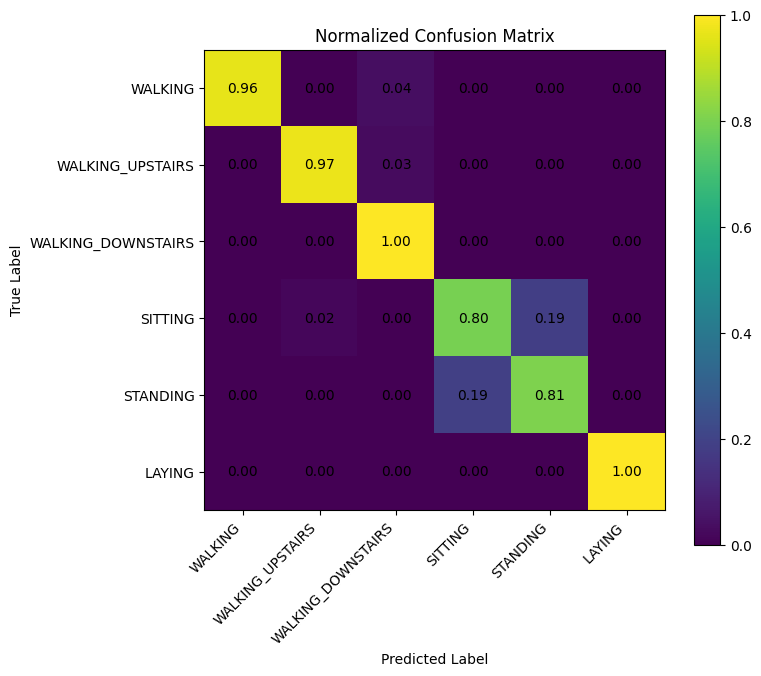

In [31]:

# ============================================================
# 20. PLOT CONFUSION MATRIX
# ============================================================

plt.figure(
    figsize=(8, 7)
)


plt.imshow(
    cm_normalized
)


plt.colorbar()


plt.xticks(

    np.arange(
        len(CLASS_NAMES)
    ),

    CLASS_NAMES,

    rotation=45,

    ha="right"
)


plt.yticks(

    np.arange(
        len(CLASS_NAMES)
    ),

    CLASS_NAMES
)


plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "Normalized Confusion Matrix"
)


for i in range(
    len(CLASS_NAMES)
):

    for j in range(
        len(CLASS_NAMES)
    ):

        plt.text(

            j,
            i,

            f"{cm_normalized[i, j]:.2f}",

            ha="center",

            va="center"
        )


plt.tight_layout()

plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


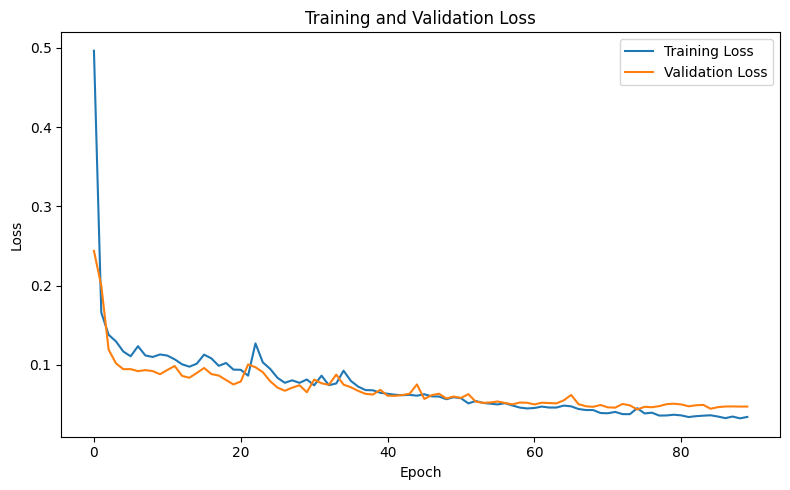

In [32]:


# ============================================================
# 21. TRAINING LOSS
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(
    history.history["loss"],
    label="Training Loss"
)


plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Training and Validation Loss"
)

plt.legend()

plt.tight_layout()

plt.show()



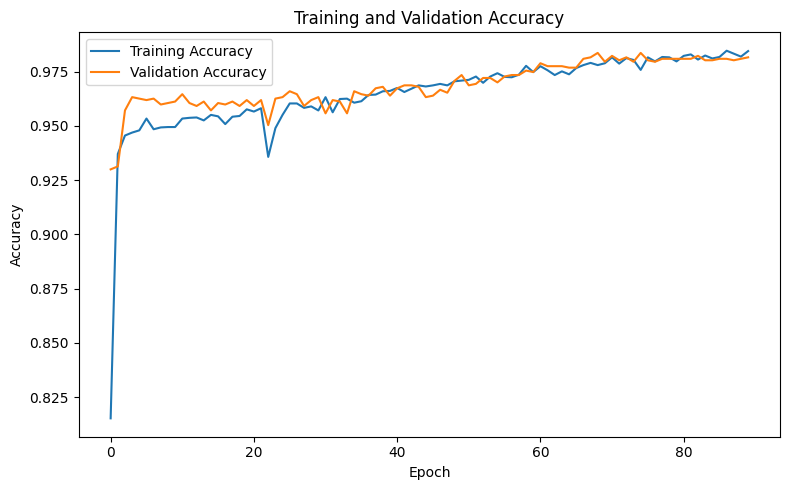


Finished.


In [33]:

# ============================================================
# 22. TRAINING ACCURACY
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)


plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Training and Validation Accuracy"
)

plt.legend()

plt.tight_layout()

plt.show()


print("\nFinished.")